In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import r2_score
from tqdm import tqdm
import matplotlib.pyplot as plt

# Find GPU devices to train on if any else cpu
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Set device to {device}")

Set device to cpu


In [2]:
# Load and cure data
PACK = "C:/Users/mpintonato/Desktop/Hackathon/artifact-hackathon-2026/challenges/surrogate-models/data/sample"
raw_data = pd.read_parquet(f"{PACK}/campaign_B_moments.parquet")
raw_data = raw_data[raw_data["group"] == "all"]
raw_data.head()

,n_stored,n_raw,n_used,present_frac,q_tot_pC,q_raw_pC,injection,xa0_mm,ts_lo,ts_hi,...,E_std_MeV,E_mad_MeV,sim_id,plane_mm,group,x_of,P_max,cN2_max,L_inj,dip_frac
0,0,0,0,0.0,0.000000e+00,1.346646e-11,False,2.0,26100,26400,...,NaN,NaN,Config_1,2.0,all,1600.887404,4928.012189,0.213508,0.479348,0.473191
1,0,0,0,0.0,0.000000e+00,1.268135e-11,False,2.1,27300,27600,...,NaN,NaN,Config_1,2.1,all,1600.887404,4928.012189,0.213508,0.479348,0.473191
2,0,0,0,0.0,0.000000e+00,9.724977e-12,False,2.2,28800,29100,...,NaN,NaN,Config_1,2.2,all,1600.887404,4928.012189,0.213508,0.479348,0.473191
3,522,522,522,1.0,5.003847e-12,9.687671e-12,False,2.3,30000,30300,...,2.64627,2.414375,Config_1,2.3,all,1600.887404,4928.012189,0.213508,0.479348,0.473191
4,3308,3308,3308,1.0,5.640687e-12,9.155769e-12,False,2.4,31500,31800,...,3.46842,2.790177,Config_1,2.4,all,1600.887404,4928.012189,0.213508,0.479348,0.473191


In [3]:
FEATURES = ["P_max", "cN2_max", "L_inj", "dip_frac", "x_of", "plane_mm"]
TARGETS = ["mean_zeta", "mean_y", "mean_z", "mean_ux", "mean_uy", "mean_uz",
           "sigma_zeta", "sigma_y", "sigma_z", "sigma_ux", "sigma_uy", "sigma_uz",
           "q_tot_pC"]

raw = pd.read_parquet(f"{PACK}/campaign_B_moments.parquet")
raw = raw[(raw["group"] == "all") & (raw["n_used"] > 0)]     # drop empty planes explicitly

def cure_dataset(df):
    out = df[["sim_id", "P_max", "cN2_max", "L_inj", "dip_frac", "x_of", "plane_mm",
              "mean_ux", "mean_uy", "mean_uz", "q_tot_pC"]].copy()
    out["mean_zeta"] = df["mean_zeta_um"]
    out["mean_y"]    = df["mean_y_um"]
    out["mean_z"]    = df["mean_z_um"]
    for name, c in zip(["zeta", "y", "z", "ux", "uy", "uz"],
                       ["cov_00", "cov_11", "cov_22", "cov_33", "cov_44", "cov_55"]):
        out[f"sigma_{name}"] = np.sqrt(df[c])
    return out.dropna()

data = cure_dataset(raw)

# Grouped split: whole simulations go to either train or test
gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=0)
tr, te = next(gss.split(data, groups=data["sim_id"]))
train_df, test_df = data.iloc[tr], data.iloc[te]

# Normalize using TRAIN statistics only
mean, std = train_df[FEATURES + TARGETS].mean(), train_df[FEATURES + TARGETS].std()
norm = lambda d: (d[FEATURES + TARGETS] - mean) / std
X_train = torch.tensor(norm(train_df)[FEATURES].to_numpy(), dtype=torch.float32, device=device)
Y_train = torch.tensor(norm(train_df)[TARGETS].to_numpy(),  dtype=torch.float32, device=device)
X_test  = torch.tensor(norm(test_df)[FEATURES].to_numpy(),  dtype=torch.float32, device=device)
Y_test  = torch.tensor(norm(test_df)[TARGETS].to_numpy(),   dtype=torch.float32, device=device)

In [24]:
# Create VAE model
def mlp(sizes):
    layers = []
    for a, b in zip(sizes[:-2], sizes[1:-1]):
        layers += [nn.Linear(a, b), nn.ReLU()]
    layers.append(nn.Linear(sizes[-2], sizes[-1]))
    return nn.Sequential(*layers)

class VAE(nn.Module):
    def __init__(self, n_in, n_out, hidden=(256, 64, 16), latent=3):
        super(VAE, self).__init__()

        self.enc = mlp([n_in, *hidden])
        self.mu = nn.Linear(hidden[-1], latent)
        self.logvar = nn.Linear(hidden[-1], latent)
        self.dec = mlp([latent, *hidden[::-1], n_out])


    def forward(self, x):
        e = self.enc(x)
        mu, logvar = self.mu(e), self.logvar(e)
        z = mu + torch.randn_like(mu) * torch.exp(0.5*logvar)
        return self.dec(z), mu, logvar

    @torch.no_grad()
    def predict(self, X):
        return self.dec(self.mu(self.enc(X)))

In [25]:
# Setup VAE loss function with KL loss
def loss_fn(y_pred, y_true, mu, logvar):
    c_loss = torch.square(y_pred - y_true).sum(-1).mean()
    kl_loss = (-0.5 * (1 + logvar - torch.square(mu) - torch.exp(logvar)).sum(-1)).mean()

    return c_loss + 1e-3*kl_loss, c_loss, kl_loss

In [26]:
# Setup Hyperparameters
EPOCHS = 500
LR = 1e-3
DATA_SIZE = X_train.shape[0]
BATCH_SIZE = 1024

In [27]:
# Setup VAE
model = VAE(n_in=len(FEATURES), n_out=len(TARGETS), hidden=(1024,512,256,128,64,32,16), latent=3).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

# Start training VAE
print("Start training VAE")
pbar = tqdm(range(EPOCHS), desc="VAE")
loss_arr = {"train": [], "test": []}

for epoch in pbar:
    tot, n = 0., 0
    # Shuffle dataset
    random_idx = torch.randperm(DATA_SIZE, device=device)
    model.train()
    # Training loop
    for start in range(0, DATA_SIZE, BATCH_SIZE): # manually indexing batch size
        idx = random_idx[start : start + BATCH_SIZE]
        x, y = X_train[idx], Y_train[idx]
        optimizer.zero_grad()
        y_pred, mu, logvar = model(x)
        loss, recon, kl = loss_fn(y_pred, y, mu, logvar)
        loss.backward()
        optimizer.step()
        tot += recon.item() * len(x)
        n += len(x)

    # Eval loop
    if epoch%5==0:
        model.eval()
        with torch.no_grad():
            pred = model.dec(model.mu(model.enc(X_test)))
            per_target = torch.square(pred - Y_test).mean(0)

        # Print info
        mse = ((model.predict(X_test) - Y_test) ** 2).mean(0)
        pbar.set_postfix(train=f"{tot / n / len(TARGETS):.4f}", test=f"{mse.mean():.3f}")
        loss_arr["train"].append(tot / n / len(TARGETS))
        loss_arr["test"].append(mse.mean())

    sched.step()

Start training VAE


VAE: 100%|██████████| 500/500 [03:01<00:00,  2.75it/s, test=0.495, train=0.0963]


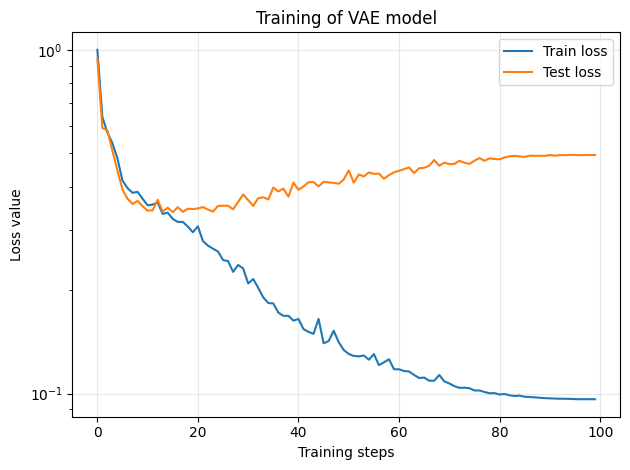

In [28]:
# Plot training loss
x = np.arange(len(loss_arr["test"]))
fig, ax = plt.subplots()
ax.semilogy(x,loss_arr["train"], label="Train loss")
ax.semilogy(x,loss_arr["test"], label="Test loss")
ax.legend()
ax.grid(alpha=0.3)
ax.set_xlabel("Training steps")
ax.set_ylabel("Loss value")
ax.set_title("Training of VAE model")
fig.tight_layout()
plt.show()

In [23]:
# Compute prediction of the trained model
model.eval()
pred = model.predict(X_test)
y_true = Y_test.cpu().numpy()
y_pred = pred.cpu().numpy()

# Compute R² score
r2 = r2_score(y_true, y_pred, multioutput="raw_values")
for col, s in zip(TARGETS, r2):
    print(f"{col:12s} R² = {s:.3f}")
print(f"{'mean':12s} R² = {r2.mean():.3f}")

mean_zeta    R² = 0.734
mean_y       R² = -0.412
mean_z       R² = -0.947
mean_ux      R² = 0.886
mean_uy      R² = -0.227
mean_uz      R² = -0.415
sigma_zeta   R² = 0.825
sigma_y      R² = 0.951
sigma_z      R² = 0.960
sigma_ux     R² = 0.912
sigma_uy     R² = 0.911
sigma_uz     R² = 0.899
q_tot_pC     R² = 0.954
mean         R² = 0.464


In [16]:
# Load test inputs
test_inputs = pd.read_parquet(f"{PACK}/test_moments_planes.parquet")

# Normalize features with TRAIN-only statistics
test_X = (test_inputs[FEATURES] - mean[FEATURES]) / std[FEATURES]
test_X = torch.tensor(test_X.to_numpy(), dtype=torch.float32, device=device)

# Predict in normalized target space (deterministic mu path)
model.eval()
with torch.no_grad():
    pred_norm = model.predict(test_X).cpu().numpy()

# Denormalize with TRAIN target statistics
pred = pred_norm * std[TARGETS].to_numpy() + mean[TARGETS].to_numpy()
submission = pd.DataFrame(pred, columns=TARGETS)

# Widths and charge can't be negative
sigma_cols = [c for c in TARGETS if c.startswith("sigma_")]
submission[sigma_cols + ["q_tot_pC"]] = submission[sigma_cols + ["q_tot_pC"]].clip(lower=0)

submission.insert(0, "config", test_inputs["config"].to_numpy())
submission.insert(1, "plane_mm", test_inputs["plane_mm"].to_numpy())

assert len(submission) == len(test_inputs)
assert not submission[TARGETS].isna().any().any()

submission.to_csv("submission_campaign_B_moments.csv", index=False)
print(f"submission_campaign_B_moments.csv  ({len(submission):,} rows)")
submission.head()

submission_campaign_B_moments.csv  (3,213 rows)


,config,plane_mm,mean_zeta,mean_y,mean_z,mean_ux,mean_uy,mean_uz,sigma_zeta,sigma_y,sigma_z,sigma_ux,sigma_uy,sigma_uz,q_tot_pC
0,1002,2.1,-16.174119,-0.033659,-0.002273,90.983718,0.012576,-0.000710,3.374449,7.005708,5.551606,22.709672,3.191500,2.198423,147.650525
1,1002,2.3,-16.920056,0.004655,0.000998,129.191081,-0.008500,0.004700,3.820291,12.317685,9.838887,38.588180,3.630756,2.521576,156.011935
2,1002,2.5,-17.926540,-0.049590,0.004887,169.736392,-0.018733,-0.003302,4.178495,18.625341,14.642989,55.431572,3.842168,2.643732,155.373590
3,1002,2.7,-18.845558,-0.048261,-0.008466,199.451634,0.026872,-0.003175,4.671284,26.381618,21.045466,68.324946,4.038155,2.773234,159.841969
4,1002,2.9,-19.134149,0.014523,-0.040037,222.530171,-0.013779,-0.002917,4.780044,32.076451,24.687624,76.074403,4.082107,2.760332,155.743209
